**Diplomatura en Ciencia de Datos, Aprendizaje Automático y sus Aplicaciones**

**Exploración y Curación de Datos**

*Edición 2026*

Grupo 5:



*   Bencharski, Constaza
*   Castro, Gerónimo
*   Riego, Daniela
*   Sequeiros, Gerónimo

Fecha:

      29/05/2026

----

# Trabajo práctico entregable - parte 2

En esta notebook, vamos a cargar el conjunto de datos de [la compentencia Kaggle](https://www.kaggle.com/dansbecker/melbourne-housing-snapshot) sobre estimación de precios de ventas de propiedades en Melbourne, Australia.

Utilizaremos el conjunto de datos reducido producido por [DanB](https://www.kaggle.com/dansbecker). Hemos subido una copia a un servidor de la Universidad Nacional de Córdoba para facilitar su acceso remoto.

In [98]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_context('talk')

from sqlalchemy import create_engine, text

In [99]:
import plotly
plotly.__version__


'5.24.1'

## Ejercicio 1 SQL:

1. Crear una base de datos en SQLite utilizando la libreria [SQLalchemy](https://stackoverflow.com/questions/2268050/execute-sql-from-file-in-sqlalchemy).
https://docs.sqlalchemy.org/en/14/core/engines.html#sqlite

2. Ingestar los datos provistos en 'https://cs.famaf.unc.edu.ar/~mteruel/datasets/diplodatos/melb_data.csv' en una tabla y el dataset generado en clase con datos de airbnb y sus precios por codigo postal en otra.

3. Validar tipos de columnas antes de guardar. Usá `df.dtypes` para ver los tipos actuales. Prestá especial atención a columnas como `Date` y `Price`: por ejemplo, `Date` puede estar como string en vez de datetime, y `Price` puede venir como string o float. El método `to_sql()` infiere tipos automáticamente, pero puede fallar si los tipos no son los esperados.

4. Implementar consultas en SQL que respondan con la siguiente información:

    - cantidad de registros totales por `Regionname`.
    - cantidad de registros totales por `Suburb` y `Regionname`.
    - Consulta con filtro: ¿Cuántas propiedades hay por `Regionname` con más de 2 habitaciones?
    - Agregación condicional: ¿Cuál es el precio promedio de propiedades según tipo (`Type`) y `Regionname`?
    - Orden y límites: Mostrá el top 5 barrios con propiedades más caras en promedio.

5. Combinar los datasets de ambas tablas ingestadas utilizando el comando JOIN de SQL para obtener un resultado similar a lo realizado con Pandas en clase.

6. Agregar una celda de validación posterior al JOIN con assertions o validación de esquema. Como mínimo, verificá que el número de filas no cambió, que no aparecieron nulos inesperados y que los rangos de variables agregadas sean razonables. Esta validación implementa dimensiones básicas de calidad de datos como validez, completitud e integridad.



# Desarrollo

Creamos un dataframe a partir del dataframe creado en clase "airbnb_price_by_zipcode.csv", que contiene las medias y medianas de los precios en la plataforma Airbnb en el área de Melbourne por día, semana y mes, según el zipcode donde se encuentran.
Por otro lado, creamos un dataframe con los datos de viviendas del área de Melbourne, provisto por la cátedra.

In [100]:
# Creamos el dataframe con los datos de Airbnb
airbnb_df_raw = pd.read_csv('./airbnb_price_by_zipcode.csv')
airbnb_df = airbnb_df_raw.copy()

# Creamos el dataframe con los datos de Melbourne
melb_df_raw = pd.read_csv('https://cs.famaf.unc.edu.ar/~mteruel/datasets/diplodatos/melb_data.csv')
melb_df = melb_df_raw.copy()


En primera instancia, observamos las cabeceras de los DataFrame para ver la disposición de los datos

In [101]:
print(airbnb_df.head())

   zipcode  airbnb_price_mean  airbnb_price_median  airbnb_record_count  \
0   2010.0          40.000000                 40.0                    1   
1   2134.0          50.000000                 50.0                    1   
2   2582.0         104.000000                104.0                    1   
3   3000.0         150.504307                129.0                 3367   
4   3001.0         132.500000                132.5                    2   

   airbnb_weekly_price_mean  airbnb_weekly_price_median  \
0                       NaN                         NaN   
1                       NaN                         NaN   
2                       NaN                         NaN   
3                918.738956                       857.0   
4                       NaN                         NaN   

   airbnb_monthly_price_mean  airbnb_monthly_price_median  
0                        NaN                          NaN  
1                        NaN                          NaN  
2             

In [102]:
print(melb_df.head())

       Suburb           Address  Rooms Type      Price Method SellerG  \
0  Abbotsford      85 Turner St      2    h  1480000.0      S  Biggin   
1  Abbotsford   25 Bloomburg St      2    h  1035000.0      S  Biggin   
2  Abbotsford      5 Charles St      3    h  1465000.0     SP  Biggin   
3  Abbotsford  40 Federation La      3    h   850000.0     PI  Biggin   
4  Abbotsford       55a Park St      4    h  1600000.0     VB  Nelson   

        Date  Distance  Postcode  ...  Bathroom  Car  Landsize  BuildingArea  \
0  3/12/2016       2.5    3067.0  ...       1.0  1.0     202.0           NaN   
1  4/02/2016       2.5    3067.0  ...       1.0  0.0     156.0          79.0   
2  4/03/2017       2.5    3067.0  ...       2.0  0.0     134.0         150.0   
3  4/03/2017       2.5    3067.0  ...       2.0  1.0      94.0           NaN   
4  4/06/2016       2.5    3067.0  ...       1.0  2.0     120.0         142.0   

   YearBuilt  CouncilArea Lattitude  Longtitude             Regionname  \
0     

Y observamos los tipos de datos presentes

In [103]:
print(melb_df.dtypes)

Suburb            object
Address           object
Rooms              int64
Type              object
Price            float64
Method            object
SellerG           object
Date              object
Distance         float64
Postcode         float64
Bedroom2         float64
Bathroom         float64
Car              float64
Landsize         float64
BuildingArea     float64
YearBuilt        float64
CouncilArea       object
Lattitude        float64
Longtitude       float64
Regionname        object
Propertycount    float64
dtype: object


In [104]:
# Convertimos la columna Date que aparece como Object a Datetime
melb_df['Date'] = pd.to_datetime(melb_df['Date'], format='%d/%m/%Y')
print(melb_df.dtypes)

Suburb                   object
Address                  object
Rooms                     int64
Type                     object
Price                   float64
Method                   object
SellerG                  object
Date             datetime64[ns]
Distance                float64
Postcode                float64
Bedroom2                float64
Bathroom                float64
Car                     float64
Landsize                float64
BuildingArea            float64
YearBuilt               float64
CouncilArea              object
Lattitude               float64
Longtitude              float64
Regionname               object
Propertycount           float64
dtype: object


Y procedemos a crear la base de datos SQLite e ingestar los datos en los dataframes como tablas

In [105]:
# Creamos la base de datos SQL
engine = create_engine('sqlite:///datasets.sqlite3', echo=False)

# Creamos la tabla SQLite de Melbourne
melb_df.to_sql(
    'melbourne_housing',
    con=engine,
    if_exists='replace',
    index=False
)

# Creamos la tabla SQLite de Airbnb
airbnb_df.to_sql(
    'airbnb',
    con=engine,
    if_exists='replace',
    index=False
)

247

Y generamos las consultas requeridas en SQL

In [106]:
# Cantidad de registros por Regionname
query1 = """
SELECT
    Regionname,
    COUNT(*) AS Registros
FROM melbourne_housing
GROUP BY Regionname
ORDER BY Registros DESC
"""
print("1. Cantidad de registros totales según Regionname:")
print("\n" + "-"*50 + "\n")
print(pd.read_sql(query1, engine))
print("\n" + "-"*50 + "\n")

1. Cantidad de registros totales según Regionname:

--------------------------------------------------

                   Regionname  Registros
0       Southern Metropolitan       4695
1       Northern Metropolitan       3890
2        Western Metropolitan       2948
3        Eastern Metropolitan       1471
4  South-Eastern Metropolitan        450
5            Eastern Victoria         53
6           Northern Victoria         41
7            Western Victoria         32

--------------------------------------------------



In [107]:
# Cantidad de registros totales por Suburb y Regionname
query2 = """
SELECT
    Regionname,
    Suburb,
    COUNT(*) AS Registros
FROM melbourne_housing
GROUP BY Regionname, Suburb
ORDER BY Registros DESC
"""
print("2. Cantidad de registros totales por Suburb y Regionname:")
print("\n" + "-"*60 + "\n")
print(pd.read_sql(query2, engine))
print("\n" + "-"*60 + "\n")

2. Cantidad de registros totales por Suburb y Regionname:

------------------------------------------------------------

                     Regionname          Suburb  Registros
0         Northern Metropolitan       Reservoir        359
1         Northern Metropolitan        Richmond        260
2         Southern Metropolitan  Bentleigh East        249
3         Northern Metropolitan         Preston        239
4         Northern Metropolitan       Brunswick        222
..                          ...             ...        ...
309  South-Eastern Metropolitan       Sandhurst          1
310        Western Metropolitan        Plumpton          1
311        Western Metropolitan        Rockbank          1
312            Western Victoria   Bacchus Marsh          1
313            Western Victoria      Brookfield          1

[314 rows x 3 columns]

------------------------------------------------------------



In [108]:
# Cuántas propiedades hay por Regionname con más de 2 habitaciones?
query3 = """
SELECT
    Regionname,
    COUNT(*) AS propiedades_mas_2habitaciones
FROM melbourne_housing
WHERE Rooms > 2
GROUP BY Regionname
ORDER BY propiedades_mas_2habitaciones DESC
"""

print("3. Consulta con filtro: ¿Cuántas propiedades hay por Regionname con más de 2 habitaciones?")
print("\n" + "-"*60 + "\n")
print(pd.read_sql(query3, engine))
print("\n" + "-"*60 + "\n")

3. Consulta con filtro: ¿Cuántas propiedades hay por Regionname con más de 2 habitaciones?

------------------------------------------------------------

                   Regionname  propiedades_mas_2habitaciones
0       Southern Metropolitan                           2848
1       Northern Metropolitan                           2389
2        Western Metropolitan                           2259
3        Eastern Metropolitan                           1228
4  South-Eastern Metropolitan                            407
5            Eastern Victoria                             50
6           Northern Victoria                             39
7            Western Victoria                             31

------------------------------------------------------------



In [109]:
# Cuál es el precio promedio de propiedades según tipo (Type) y Regionname?
query4 = """
SELECT
    Regionname,
    Type,
    AVG(Price) AS Precio_promedio
FROM melbourne_housing
GROUP BY Regionname, Type
HAVING COUNT(*) >= 10
ORDER BY Precio_promedio DESC
"""

print("4. Agregación condicional: ¿Cuál es el precio promedio de propiedades según tipo (Type) y Regionname?")
print("\n" + "-"*50 + "\n")
print(pd.read_sql(query4, engine))
print("\n" + "-"*50 + "\n")

4. Agregación condicional: ¿Cuál es el precio promedio de propiedades según tipo (Type) y Regionname?

--------------------------------------------------

                    Regionname Type  Precio_promedio
0        Southern Metropolitan    h     1.802241e+06
1        Southern Metropolitan    t     1.205404e+06
2         Eastern Metropolitan    h     1.197450e+06
3        Northern Metropolitan    h     1.021222e+06
4   South-Eastern Metropolitan    h     9.559496e+05
5         Western Metropolitan    h     9.507663e+05
6   South-Eastern Metropolitan    t     9.132700e+05
7         Eastern Metropolitan    t     8.696199e+05
8        Northern Metropolitan    t     7.496083e+05
9         Western Metropolitan    t     7.209510e+05
10            Eastern Victoria    h     7.142996e+05
11       Southern Metropolitan    u     6.648600e+05
12        Eastern Metropolitan    u     6.493144e+05
13           Northern Victoria    h     5.948293e+05
14  South-Eastern Metropolitan    u     5.833649e+

In [110]:
# Top 5 barrios con propiedades más caras en promedio.
query5 = """
SELECT
    Suburb,
    AVG(Price) AS Precio_promedio
FROM melbourne_housing
GROUP BY Suburb
HAVING COUNT(*) >= 10
ORDER BY Precio_promedio DESC
LIMIT 5
"""

print("5. Orden y límites: Mostrá el top 5 barrios con propiedades más caras en promedio.")
print("\n" + "-"*50 + "\n")
print(pd.read_sql(query5, engine))
print("\n" + "-"*50 + "\n")

5. Orden y límites: Mostrá el top 5 barrios con propiedades más caras en promedio.

--------------------------------------------------

        Suburb  Precio_promedio
0   Canterbury     2.180241e+06
1  Middle Park     2.082529e+06
2  Albert Park     1.941355e+06
3     Brighton     1.930158e+06
4       Balwyn     1.869879e+06

--------------------------------------------------



Ahora ejecutamos el comando JOIN de las tablas SQL en un dataframe por zipcode/postcode


In [111]:
# Armamos un query que haga el JOIN de las tablas por postcode/zipcode

join_query = """
SELECT
    m.*,
    a.*
FROM melbourne_housing m
LEFT JOIN airbnb a
    ON m.Postcode = a.zipcode
"""

# Ejecutamos el query de join y creamos el dataframe conjunto
joined_df = pd.read_sql(join_query, engine)
# Eliminamos la columna zipcode, ya que es redundante
joined_df = joined_df.drop(columns=['zipcode'])
# verificamos que no haya cambiado la cantidad de filas del dataframe
assert len(joined_df) == len(melb_df)

print(joined_df.head())



       Suburb           Address  Rooms Type      Price Method SellerG  \
0  Abbotsford      85 Turner St      2    h  1480000.0      S  Biggin   
1  Abbotsford   25 Bloomburg St      2    h  1035000.0      S  Biggin   
2  Abbotsford      5 Charles St      3    h  1465000.0     SP  Biggin   
3  Abbotsford  40 Federation La      3    h   850000.0     PI  Biggin   
4  Abbotsford       55a Park St      4    h  1600000.0     VB  Nelson   

                         Date  Distance  Postcode  ...  Longtitude  \
0  2016-12-03 00:00:00.000000       2.5    3067.0  ...    144.9984   
1  2016-02-04 00:00:00.000000       2.5    3067.0  ...    144.9934   
2  2017-03-04 00:00:00.000000       2.5    3067.0  ...    144.9944   
3  2017-03-04 00:00:00.000000       2.5    3067.0  ...    144.9969   
4  2016-06-04 00:00:00.000000       2.5    3067.0  ...    144.9941   

              Regionname  Propertycount  airbnb_price_mean  \
0  Northern Metropolitan         4019.0         130.624031   
1  Northern Metr

Y agregamos validaciones de completitud, rango y prescencia de duplicados:

In [112]:
# Validacion de completitud
print("\n" + "-"*50 + "\n")


porcentaje_nulos = airbnb_df['airbnb_price_mean'].isnull().mean()
porcentaje_nulos_joined = joined_df['airbnb_price_mean'].isnull().mean()

print(f"Porcentaje de nulos en airbnb_price_mean en el dataframe primitivo: {porcentaje_nulos:.2%}")
print(f"Porcentaje de nulos en airbnb_price_mean en el dataframe fusionado: {porcentaje_nulos_joined:.2%}")

# Verificar que los nulos en joined_df corresponden a zipcodes sin match
# Obtener los postcodes en joined_df que resultaron en NaN para airbnb_price_mean
postcodes_with_nan_airbnb = joined_df[joined_df['airbnb_price_mean'].isnull()]['Postcode'].unique()

# Obtener los zipcodes únicos del dataframe original de airbnb
original_airbnb_zipcodes = airbnb_df['zipcode'].unique()

# Verificar que ninguno de los postcodes con NaN en joined_df esté en los zipcodes originales de airbnb
# Si esta afirmación pasa, significa que los NaNs fueron introducidos correctamente por el LEFT JOIN
assert all(p not in original_airbnb_zipcodes for p in postcodes_with_nan_airbnb), \
    "Error: Se encontraron nulos en airbnb_price_mean para postcodes que sí existen en airbnb_df."

print(f"Verificación de nulos por `Postcode` sin match: OK. Se encontraron {len(postcodes_with_nan_airbnb)} `Postcode` que no tuvieron match en `airbnb_df` y resultaron en `NaN` en el dataframe fusionado.")

print("\n" + "-"*50 + "\n")

# Validacion de rangos

assert joined_df['Price'].min() >= 0, \
    "Hay precios negativos"
assert joined_df['airbnb_price_mean'].dropna().min() >= 0, \
    "Hay precios Airbnb negativos"

print(f"Verificación de rango de valores de precios correcta. No hay valores de precios negativos en el dataframe fusionado.")

# Verificar que el rango de precios en el dataframe original y el fusionado sean iguales
assert melb_df['Price'].min() == joined_df['Price'].min() and \
       melb_df['Price'].max() == joined_df['Price'].max(), \
       "Error: El rango de precios ('Price') ha cambiado después de la fusión."
print(f"Verificación del rango de precios entre melb_df y joined_df correcta. Los rangos son consistentes.")

print("\n" + "-"*50 + "\n")


# Validacion de duplicados

duplicados = joined_df.duplicated().sum()

print(f"Duplicados totales: {duplicados}")
print("\n" + "-"*50 + "\n")

# Verificación de dimension del dataframe

print(f"Tamaño del Dataframe melb_df: {melb_df.shape}")
print(f"Tamaño del Dataframe airbnb_df: {airbnb_df.shape}")
print(f"Tamaño del Dataframe joined_df: {joined_df.shape}")

print("\n" + "-"*50 + "\n")


--------------------------------------------------

Porcentaje de nulos en airbnb_price_mean en el dataframe primitivo: 0.00%
Porcentaje de nulos en airbnb_price_mean en el dataframe fusionado: 0.15%
Verificación de nulos por `Postcode` sin match: OK. Se encontraron 7 `Postcode` que no tuvieron match en `airbnb_df` y resultaron en `NaN` en el dataframe fusionado.

--------------------------------------------------

Verificación de rango de valores de precios correcta. No hay valores de precios negativos en el dataframe fusionado.
Verificación del rango de precios entre melb_df y joined_df correcta. Los rangos son consistentes.

--------------------------------------------------

Duplicados totales: 0

--------------------------------------------------

Tamaño del Dataframe melb_df: (13580, 21)
Tamaño del Dataframe airbnb_df: (247, 8)
Tamaño del Dataframe joined_df: (13580, 28)

--------------------------------------------------



Se verificó que los valores nulos presentes en el dataframe fusionado corresponden a columnas donde no hubo coincidencia durante el proceso de JOIN. Además, se constató que el nuevo dataframe no tiene datos duplicados, que el rango de valores de precios es acorde y que las dimensiones esperadas para el dataframe fusionado son correctas.

## Ejercicio 2 - Pandas:

Este ejercicio usa el archivo `airbnb_price_by_zipcode.csv` generado en el notebook `02.1 Combinación de datasets.ipynb`. Si no lo tenés, generarlo primero antes de comenzar esta parte.

1. Seleccionar un subconjunto de columnas que les parezcan relevantes al problema de predicción del valor de la propiedad. Justificar explicitamente las columnas seleccionadas y las que no lo fueron.
  1. Valores faltantes: ¿Qué porcentaje de filas tienen al menos un valor faltante?
  2. Mostrar la dispersión o distribución de las columnas seleccionadas.
 3. Eliminar los valores extremos que no sean relevantes para la predicción de valores de las propiedades.
 4. Mostrar visualmente los valores extremos que eliminás


2. Agregar información adicional respectiva al entorno de una propiedad a partir del [conjunto de datos de AirBnB](https://www.kaggle.com/tylerx/melbourne-airbnb-open-data?select=cleansed_listings_dec18.csv) utilizado en el práctico.
  1. Seleccionar qué variables agregar y qué combinaciones aplicar a cada una. Por ejemplo, pueden utilizar solo la columna `price`, o aplicar múltiples transformaciones como la mediana (¿por qué no la media?) o el mínimo.
  2. Utilizar la variable zipcode para unir los conjuntos de datos. Sólo incluir los zipcodes que tengan una cantidad mínima de registros (a elección) como para que la información agregada sea relevante.
  3. Mostrar un gráfico zipcode vs airbnb_price_median.
  4. Investigar al menos otras 2 variables que puedan servir para combinar los datos, y justificar si serían adecuadas o no. Pueden asumir que cuentan con la ayuda de anotadores expertos para encontrar equivalencias entre barrios o direcciones, o que cuentan con algoritmos para encontrar las n ubicaciones más cercanas a una propiedad a partir de sus coordenadas geográficas. **NO** es necesario que realicen la implementación. Si tuvieras que entrevistar a un experto inmobiliario para mapear barrios entre datasets, ¿qué 3 preguntas le harías para validar esa correspondencia?
  5. Si las coordenadas geoespaciales estuvieran disponibles, como las usarian?

Pueden leer otras columnas del conjunto de AirBnB además de las que están en `interesting_cols`, si les parecen relevantes.

¿Qué cosas no están en los datos que te gustaría tener para predecir mejor el precio de una propiedad?


#2) Desarrollo

Observamos los tipos de datos:

In [113]:
#
print(melb_df.dtypes)

Suburb                   object
Address                  object
Rooms                     int64
Type                     object
Price                   float64
Method                   object
SellerG                  object
Date             datetime64[ns]
Distance                float64
Postcode                float64
Bedroom2                float64
Bathroom                float64
Car                     float64
Landsize                float64
BuildingArea            float64
YearBuilt               float64
CouncilArea              object
Lattitude               float64
Longtitude              float64
Regionname               object
Propertycount           float64
dtype: object


Para predecir el valor de la propiedad, sin tener en cuenta el dato 'Price', tenemos, por un lado, las variables que describen las particularidades de la propiedad en si misma y, por otro, las que dan información de su entorno, las cuales también puede influir en el precio, por ejemplo, el caso de encontrarse la vivienda en un barrio más caro que otro.
De las variables de localización puede tomarse 'Suburb', que es la que más está relacionada al supuesto de que el barrio afecta el precio de la propiedad.
Las variables propias de la casa que influyen en el valor son: 'Rooms', 'Type', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt'.

In [114]:
# Columnas informativas sobre el precio
informative_cols = ['Suburb', 'Rooms', 'Type', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt']
# Dataframe con columnas informativas
melb_inf_df   = melb_df[informative_cols]

# Cuántos nulos hay en cada columna?
porcentaje_nulos = melb_inf_df.isnull().sum() * 100 / len(melb_inf_df)
print(f"Porcentaje de nulos en airbnb_price_mean:")
print(porcentaje_nulos)

Porcentaje de nulos en airbnb_price_mean:
Suburb           0.000000
Rooms            0.000000
Type             0.000000
Bathroom         0.000000
Car              0.456554
Landsize         0.000000
BuildingArea    47.496318
YearBuilt       39.580265
dtype: float64


Observamos, luego, la dispersión de las variables seleccionadas:

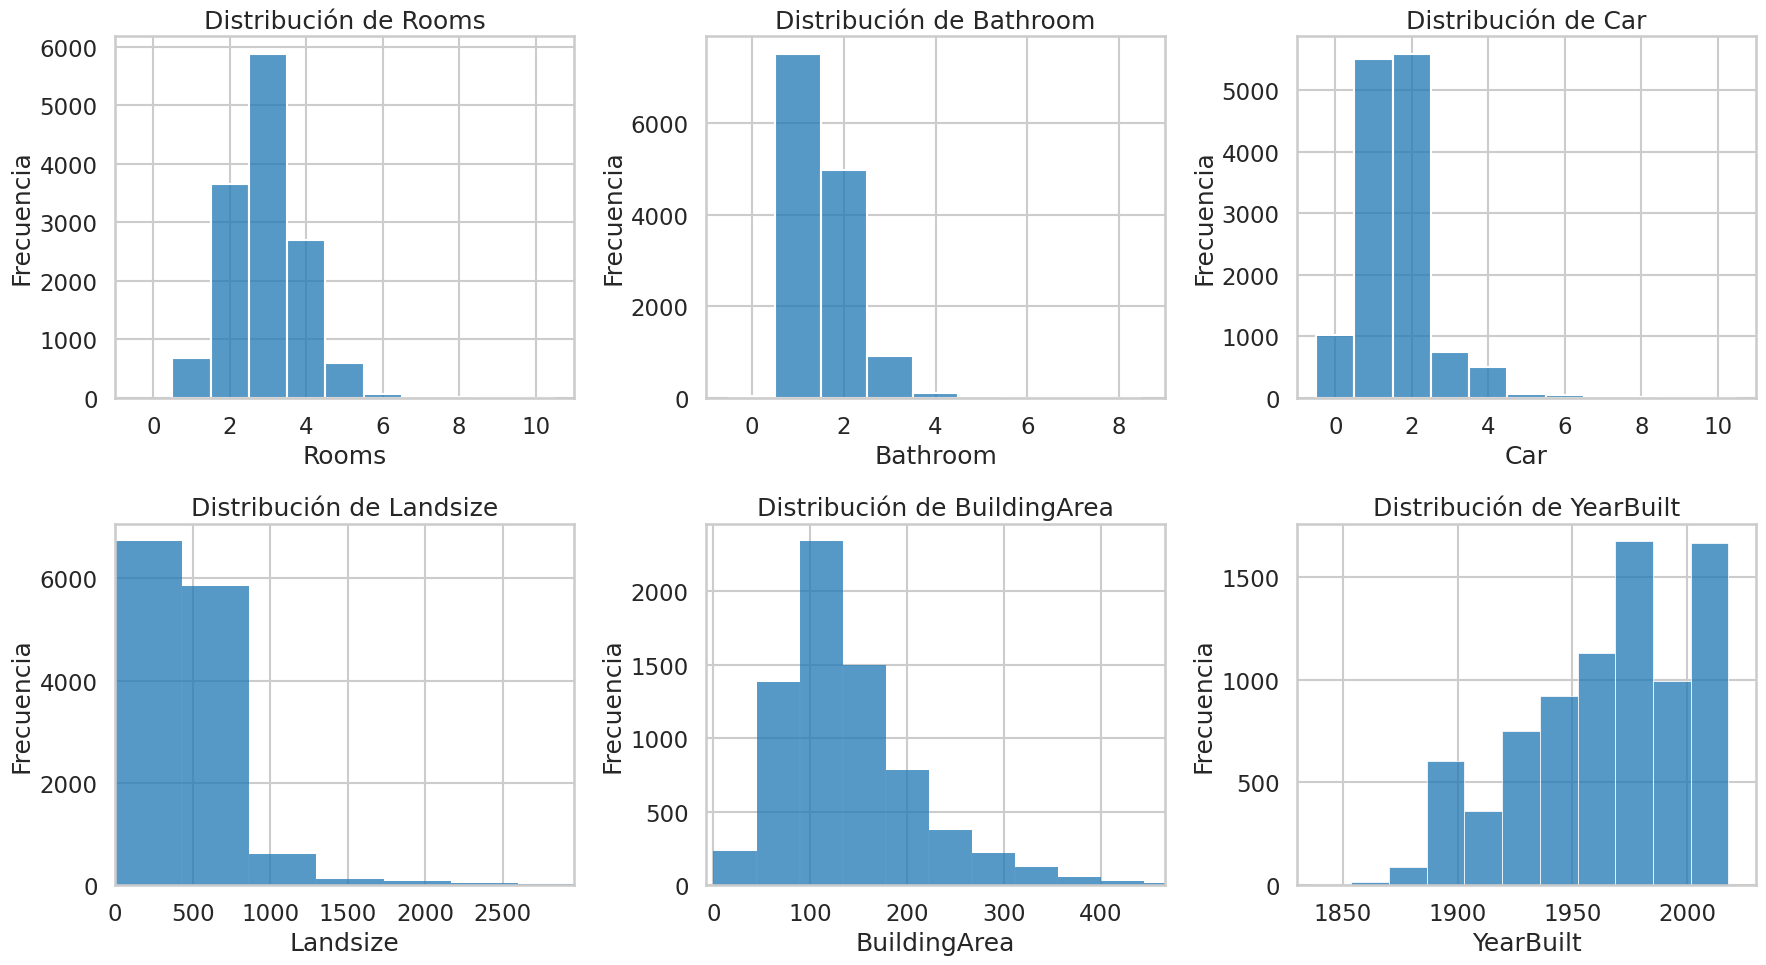

In [115]:
# Visualizacion de variables numéricas

# Figura y ejes
sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Rooms
sns.histplot(
    data=melb_df,
    x='Rooms',
    discrete=True,
    ax=axes[0, 0]
)
axes[0, 0].set_xlim( -1 , 11)
axes[0, 0].set_title('Distribución de Rooms')
axes[0, 0].set_xlabel('Rooms')
axes[0, 0].set_ylabel('Frecuencia')

# Bathroom
sns.histplot(
    data=melb_df,
    x='Bathroom',
    discrete=True,
    ax=axes[0, 1]
)
axes[0, 1].set_xlim( -1 , 9)
axes[0, 1].set_title('Distribución de Bathroom')
axes[0, 1].set_xlabel('Bathroom')
axes[0, 1].set_ylabel('Frecuencia')

# Car
sns.histplot(
    data=melb_df,
    x='Car',
    discrete=True,
    ax=axes[0, 2]
)
axes[0, 2].set_xlim( -1 , 11)
axes[0, 2].set_title('Distribución de Car')
axes[0, 2].set_xlabel('Car')
axes[0, 2].set_ylabel('Frecuencia')

# Landsize
sns.histplot(
    data=melb_df,
    x='Landsize',
    bins=1000,
    ax=axes[1, 0]
)
axes[1, 0].set_xlim(-melb_df.Landsize.quantile(0.01), melb_df.Landsize.quantile(0.99))
axes[1, 0].set_title('Distribución de Landsize')
axes[1, 0].set_xlabel('Landsize')
axes[1, 0].set_ylabel('Frecuencia')

# BuildingArea
sns.histplot(
    data=melb_df,
    x='BuildingArea',
    bins=1000,
    ax=axes[1, 1]
)
axes[1, 1].set_xlim(-melb_df.BuildingArea.quantile(0.01), melb_df.BuildingArea.quantile(0.99))
axes[1, 1].set_title('Distribución de BuildingArea')
axes[1, 1].set_xlabel('BuildingArea')
axes[1, 1].set_ylabel('Frecuencia')

# YearBuilt
sns.histplot(
    data=melb_df,
    x='YearBuilt',
    bins=50,
    ax=axes[1, 2]
)
axes[1, 2].set_xlim(1830, 2030)
axes[1, 2].set_title('Distribución de YearBuilt')
axes[1, 2].set_xlabel('YearBuilt')
axes[1, 2].set_ylabel('Frecuencia')

# Ajuste final
plt.tight_layout()
plt.show()

Analizando estos gráficos, podemos ver los rangos de valores que toman estas variables.
Generamos un dataframe filtrando los valores extremos

In [116]:
# Armamos una matriz con condiciones para filtrar los datos
conditions = np.ones(len(melb_df), dtype=bool)
num_cols = ['Rooms', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt']
#conditions = np.ones(len(melb_df), dtype=bool)
conditions &= (
    (melb_df['Rooms'] >= 0) &  (melb_df['Rooms'] <= 6) &
    (melb_df['Bathroom'] >= 0) &  (melb_df['Bathroom'] <= 4) &
    (melb_df['Car'] >= 0) &  (melb_df['Car'] <= 6) &
    (melb_df['Landsize'] >= 15) &  (melb_df['Landsize'] <= 2500) &
    (melb_df['BuildingArea'] >= 15) &  (melb_df['BuildingArea'] <= 400) &
    (melb_df['YearBuilt'] >= 1850) &  (melb_df['YearBuilt'] <= 2020)
)
#discard_masks = np.ones(len(melb_df), dtype=bool)
discard_masks = {
    'Rooms': ((melb_inf_df['Rooms'] < 0) | (melb_inf_df['Rooms'] > 6)),
    'Bathroom': ((melb_inf_df['Bathroom'] < 0) | (melb_inf_df['Bathroom'] > 4)),
    'Car': ((melb_inf_df['Car'] < 0) | (melb_inf_df['Car'] > 6)),
    'Landsize': ((melb_inf_df['Landsize'] < 15) | (melb_inf_df['Landsize'] > 2500)),
    'BuildingArea': ((melb_inf_df['BuildingArea'] < 15) | (melb_inf_df['BuildingArea'] > 400)),
    'YearBuilt': ((melb_inf_df['YearBuilt'] < 1850) | (melb_inf_df['YearBuilt'] > 2020))
}

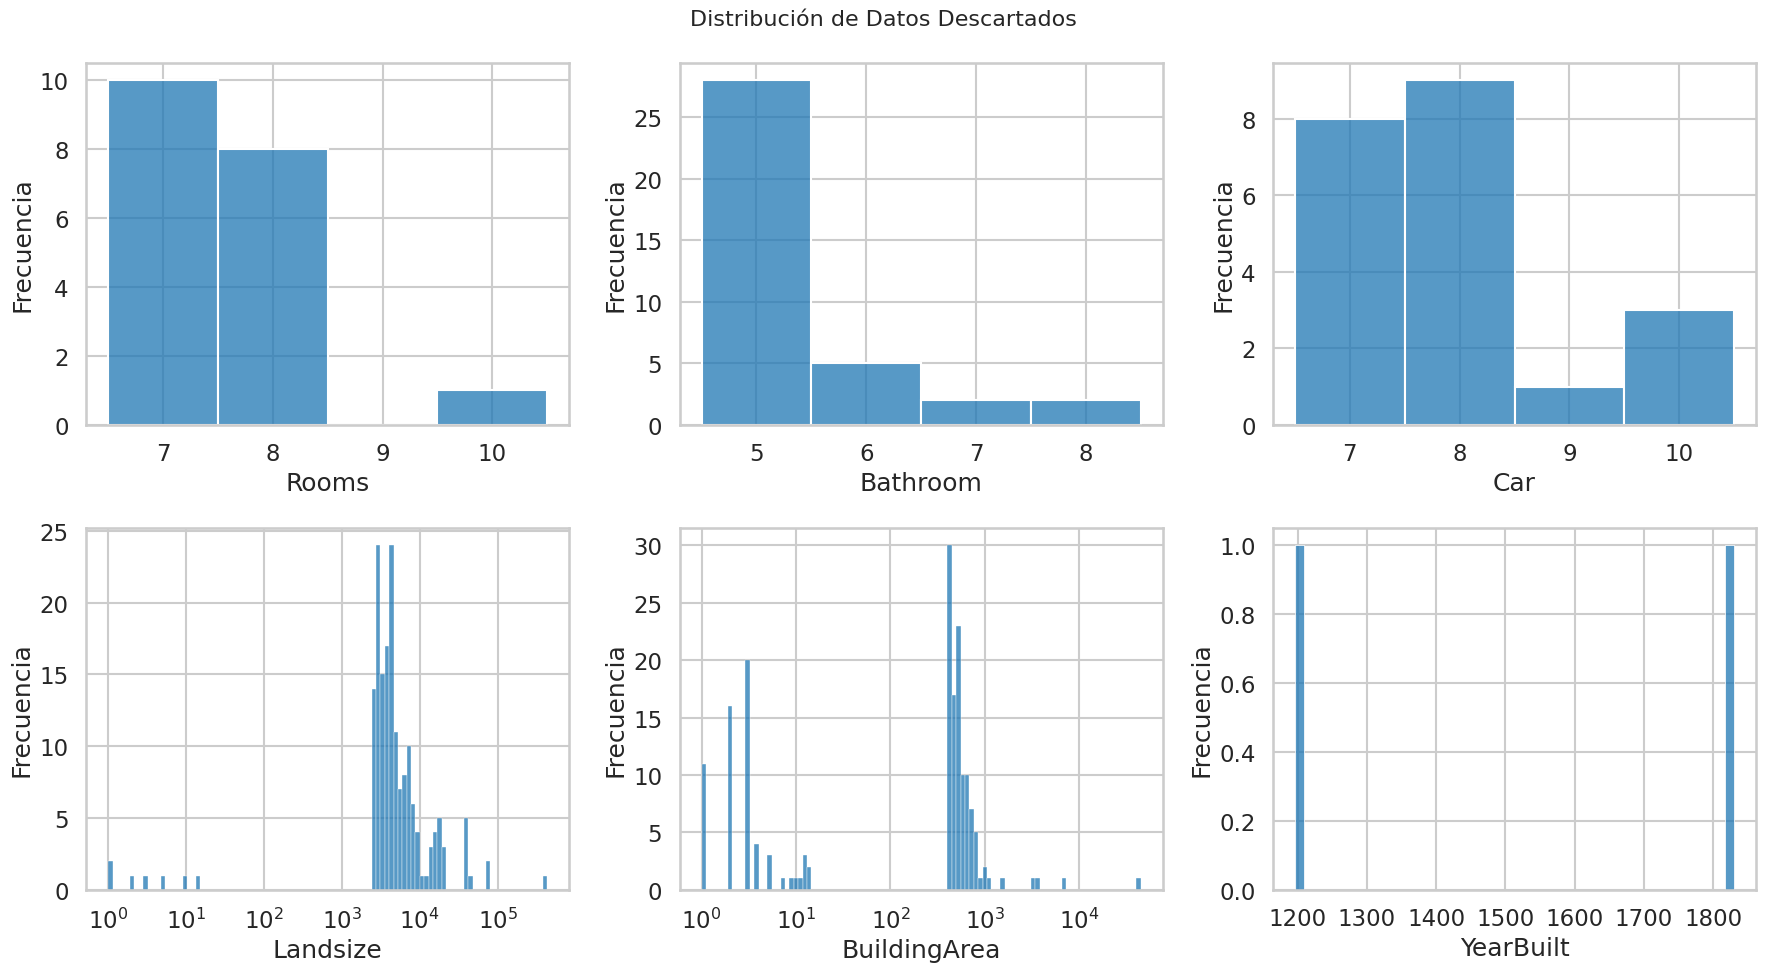

In [117]:
# Visualizamos los datos descartados
# Figura y ejes
sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Distribución de Datos Descartados', fontsize=16)

# Rooms
sns.histplot(
    data=melb_inf_df[discard_masks['Rooms']],
    x='Rooms',
    discrete=True,
    ax=axes[0, 0]
)
axes[0, 0].set_xlabel('Rooms')
axes[0, 0].set_ylabel('Frecuencia')

# Bathroom
sns.histplot(
    data=melb_inf_df[discard_masks['Bathroom']],
    x='Bathroom',
    discrete=True,
    ax=axes[0, 1]
)
axes[0, 1].set_xlabel('Bathroom')
axes[0, 1].set_ylabel('Frecuencia')

# Car
sns.histplot(
    data=melb_inf_df[discard_masks['Car']],
    x='Car',
    discrete=True,
    ax=axes[0, 2]
)
axes[0, 2].set_xlabel('Car')
axes[0, 2].set_ylabel('Frecuencia')

# Landsize
sns.histplot(
    data=melb_inf_df[discard_masks['Landsize']],
    x='Landsize',
    bins=100,
    log_scale=True,
    ax=axes[1, 0]
)
axes[1, 0].set_xlabel('Landsize')
axes[1, 0].set_ylabel('Frecuencia')

# BuildingArea
sns.histplot(
    data=melb_inf_df[discard_masks['BuildingArea']],
    x='BuildingArea',
    bins=100,
    log_scale=True,
    ax=axes[1, 1]
)
axes[1, 1].set_xlabel('BuildingArea')
axes[1, 1].set_ylabel('Frecuencia')

# YearBuilt
sns.histplot(
    data=melb_inf_df[discard_masks['YearBuilt']],
    x='YearBuilt',
    bins=50,
    ax=axes[1, 2]
)
axes[1, 2].set_xlabel('YearBuilt')
axes[1, 2].set_ylabel('Frecuencia')

# Ajuste final
plt.tight_layout()
plt.show()

Y observamos los datos remanentes:

In [118]:
# Datos filtrados y descartados
melb_inf_df_filtered = melb_inf_df[conditions]
# porcentaje de datos Remanentes
porcentaje_remanentes = melb_inf_df_filtered.shape[0] / melb_inf_df.shape[0]
print(f"Porcentaje de datos remanentes: {porcentaje_remanentes:.2%}")

Porcentaje de datos remanentes: 41.10%


Además de las filas que no cumplen con las condiciones, se descartan las filas que tienen NaNs y por eso nos quedamos con el 41% de los datos. Es por eso, que decidimos usar el DataFrame generado en el Entregable N°1 de este curso, donde se realizó una curación de datos y se imputaron los valores numéricos faltantes.

In [119]:
# Creamos el dataframe con los datos de prpiedades de Melbourne procesados en el Entregable 1
melb_processed_raw = pd.read_csv('./melb_processed.csv')
melb_processed = melb_processed_raw.copy()

In [120]:
melb_processed.shape

(13580, 18)

In [121]:
melb_processed.dtypes

,0
Rooms,float64
Price,float64
Distance,float64
Postcode,float64
Bathroom,float64
Car,float64
Landsize,float64
Lattitude,float64
Longtitude,float64
Propertycount,float64


2.1 Vamos a analizar la correlación entre las variables numéricas para establecer un criterio con respecto a la columna "Price" para descartar algunas columnas que nos den información redundante.

In [122]:
numeric_cols = melb_processed.select_dtypes(include=[np.number])
corr = numeric_cols.corr()
corr.Price.sort_values(ascending=False)

,Price
Price,1.000000
PC1,0.666946
BuildingArea,0.603032
Rooms,0.496634
Bathroom,0.468818
Car,0.237497
Longtitude,0.203656
Postcode,0.107867
Landsize,0.004332
PC2,-0.007330


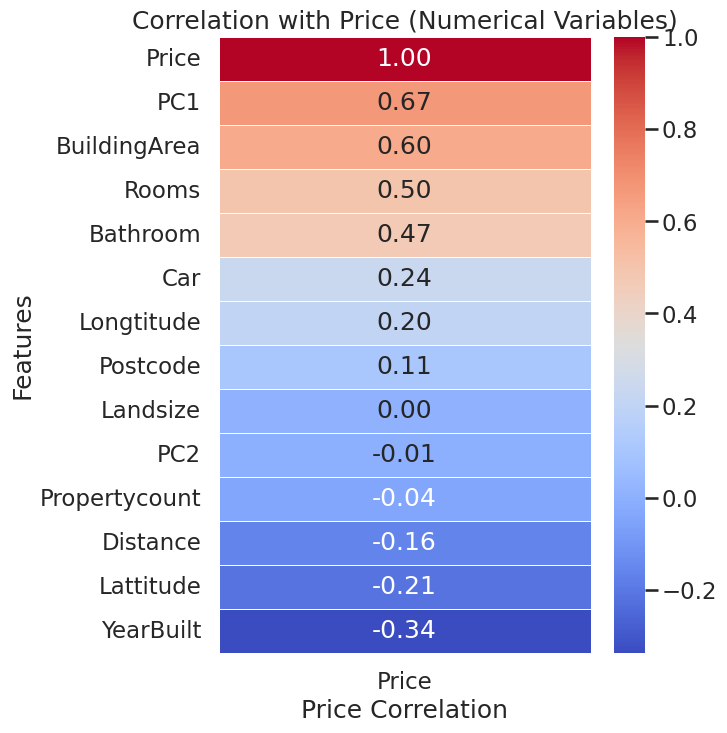

In [123]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get the correlation of numerical columns with 'Price'
price_correlations = corr[['Price']].sort_values(by='Price', ascending=False)

# Create a heatmap
plt.figure(figsize=(6, 8))
sns.heatmap(price_correlations, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation with Price (Numerical Variables)')
plt.xlabel('Price Correlation')
plt.ylabel('Features')
plt.show()

Viendo las correlaciones de las variables numéricas con "Price" decidimos quedarnos con "BuldingArea", "Rooms", "Bathrooms" y "YearBuilt" que tienen más de un 30% de correlación con la variable "Price". Las componentes principales PC1 y PC2 no son tenidas en cuenta porque en su definición contienen en cierto término a la variable Price, la cuál asumimos desconocida.

Con respecto a las variables categóricas, decidimos quedarnos con "Suburb" y "Type", puesto que el tipo de propiedad (habitación, monoambiente, casa, etc.), así como el barrio donde la misma se ubica son variables que modifican fuertemente el precio de una propiedad.

In [124]:
# Atributos relevantes
columnas_relevantes = ['Rooms','Bathroom','BuildingArea','YearBuilt','Type','Suburb', 'Postcode']
#Dataframe con columnas relevantes
melb_relev = melb_processed[columnas_relevantes].copy()
# melb_relev.head()
melb_relev.shape

(13580, 7)

Dado que melb_relev es un DataFrame que se desprende del práctico anterior, el mismo tiene sus datos imputados y filtrados y no contiene datos faltantes.

2.6 - 2.7 - 2.8 Utilizaremos el dataset creado en clase  `airbnb_price_by_zipcode.csv`.

In [134]:
print(airbnb_df.head())

   zipcode  airbnb_price_mean  airbnb_price_median  airbnb_record_count  \
0   2010.0          40.000000                 40.0                    1   
1   2134.0          50.000000                 50.0                    1   
2   2582.0         104.000000                104.0                    1   
3   3000.0         150.504307                129.0                 3367   
4   3001.0         132.500000                132.5                    2   

   airbnb_weekly_price_mean  airbnb_weekly_price_median  \
0                       NaN                         NaN   
1                       NaN                         NaN   
2                       NaN                         NaN   
3                918.738956                       857.0   
4                       NaN                         NaN   

   airbnb_monthly_price_mean  airbnb_monthly_price_median  
0                        NaN                          NaN  
1                        NaN                          NaN  
2             

Analizamos los datos faltantes:

In [126]:
nans_airbnb_price_mean = airbnb_df['airbnb_price_mean'].isnull().sum() / len(airbnb_df) * 100
nans_airbnb_weekly_price_mean = airbnb_df['airbnb_weekly_price_mean'].isnull().sum() / len(airbnb_df) * 100
nans_airbnb_monthly_price_mean = airbnb_df['airbnb_monthly_price_mean'].isnull().sum() / len(airbnb_df) * 100

print(f"Porcentaje de NaN en 'airbnb_price_mean': {nans_airbnb_price_mean:.2f}%")
print(f"Porcentaje de NaN en 'airbnb_weekly_price_mean': {nans_airbnb_weekly_price_mean:.2f}%")
print(f"Porcentaje de NaN en 'airbnb_monthly_price_mean': {nans_airbnb_monthly_price_mean:.2f}%")

Porcentaje de NaN en 'airbnb_price_mean': 0.00%
Porcentaje de NaN en 'airbnb_weekly_price_mean': 25.51%
Porcentaje de NaN en 'airbnb_monthly_price_mean': 31.98%


Para el análisis posterior, nos quedaremos con los valores de zipcode que tengan al menos 10 registros. Observamos que, de esta manera, se analizan aproximádamente el 74% de los datos.

In [127]:
# Para el análisis vamos a quedarnos con los zipcodes que tengan al menos 10 cuentas(propiedades)
airbnb_df_2 = airbnb_df[airbnb_df.airbnb_record_count >= 10]

# Calcular y mostrar el porcentaje de datos que esto representa del total
reten = (len(airbnb_df_2) / len(airbnb_df)) * 100
print(f"El dataframe airbnb_df_2 representa el {reten:.2f}% de los datos totales de airbnb_df.")

El dataframe airbnb_df_2 representa el 73.68% de los datos totales de airbnb_df.


Observamos la variación de la media y la mediana de los precios según el zipcode. Observamos que, como es de esperar, la mediana es una medida más robusta ante valores extremos, por ello será la variable usada para los análisis posteriores.

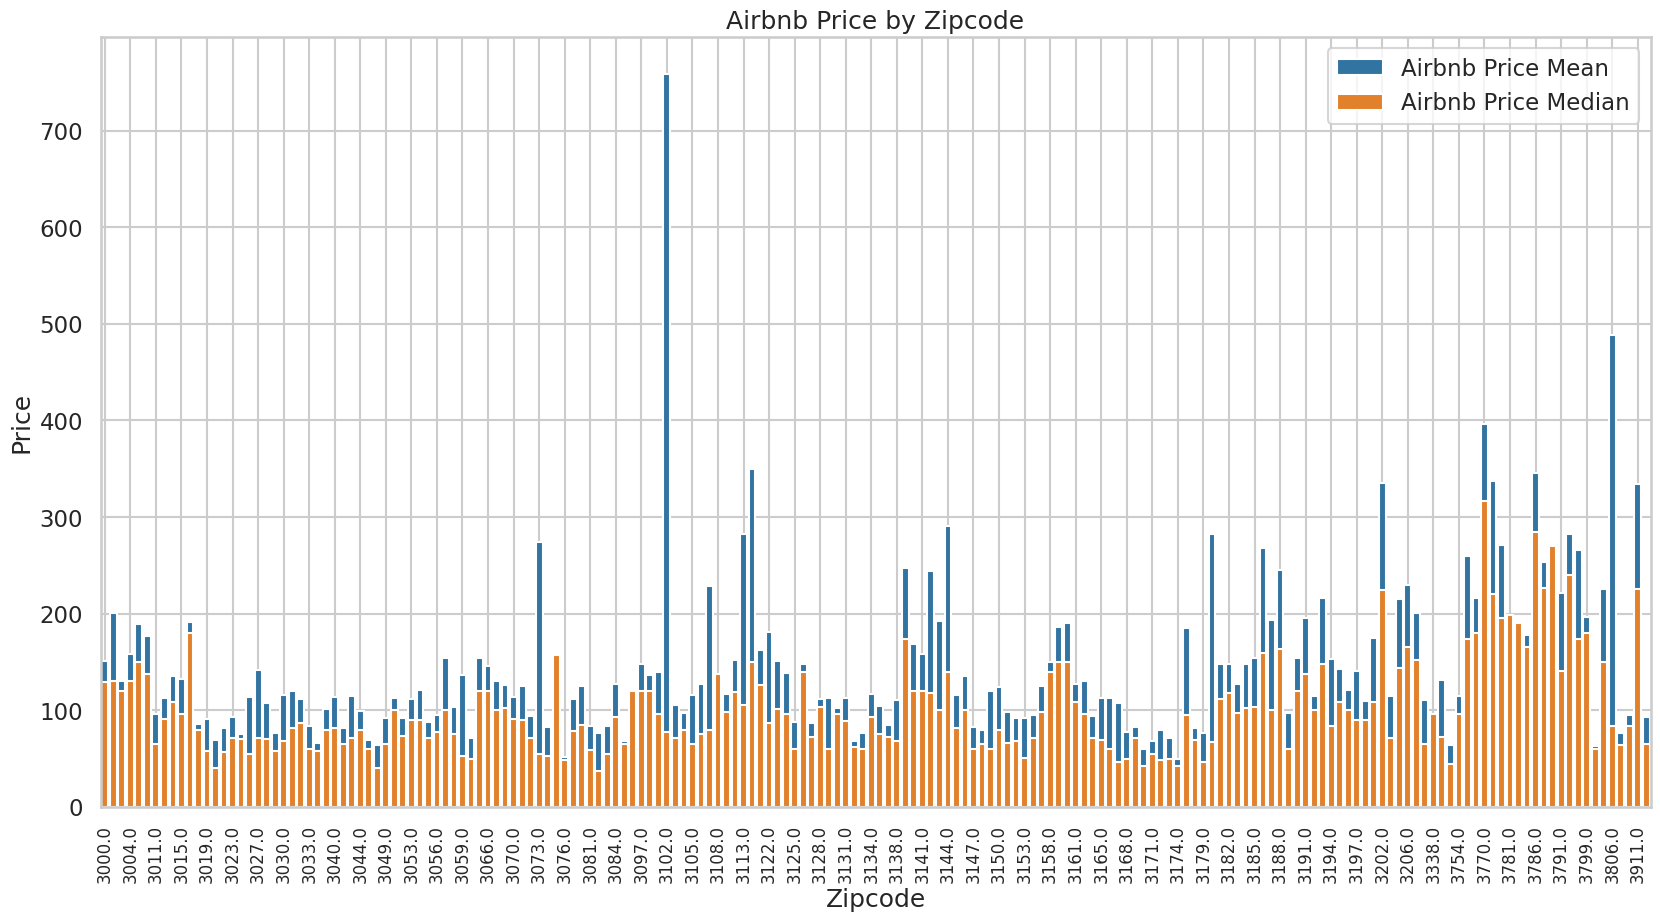

In [128]:
plt.figure(figsize=(20, 10))
sns.barplot(x='zipcode', y='airbnb_price_mean', data=airbnb_df_2, label='Airbnb Price Mean')
sns.barplot(x='zipcode', y='airbnb_price_median', data=airbnb_df_2, label='Airbnb Price Median')
plt.title('Airbnb Price by Zipcode')
plt.xlabel('Zipcode')
plt.xticks(ticks=range(0, len(airbnb_df_2['zipcode']), 3))
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.xticks(rotation=90, fontsize=12)
plt.show()

Luego, agregamos los datos de las medianas de los precios al dataframe meld_processed, buscando coincidencias usando la variable "Postcode".

In [129]:
melbnb_df = melb_relev.merge(airbnb_df_2[['airbnb_price_median', 'zipcode']], left_on="Postcode", right_on="zipcode")
melbnb_df.dtypes

,0
Rooms,float64
Bathroom,float64
BuildingArea,float64
YearBuilt,float64
Type,object
Suburb,object
Postcode,float64
airbnb_price_median,float64
zipcode,float64


In [130]:
melbnb_df = melbnb_df.drop(columns=['Postcode'])
melbnb_df.dtypes

,0
Rooms,float64
Bathroom,float64
BuildingArea,float64
YearBuilt,float64
Type,object
Suburb,object
airbnb_price_median,float64
zipcode,float64


2.10/11 - Investigar al menos otras 2 variables que puedan servir para combinar los datos, y justificar si serían adecuadas o no. Pueden asumir que cuentan con la ayuda de anotadores expertos para encontrar equivalencias entre barrios o direcciones, o que cuentan con algoritmos para encontrar las n ubicaciones más cercanas a una propiedad a partir de sus coordenadas geográficas. NO es necesario que realicen la implementación. Si tuvieras que entrevistar a un experto inmobiliario para mapear barrios entre datasets, ¿qué 3 preguntas le harías para validar esa correspondencia?
- Si las coordenadas geoespaciales estuvieran disponibles, como las usarian?
- ¿Qué cosas no están en los datos que te gustaría tener para predecir mejor el precio de una propiedad?

---

Otra forma de combinar los datos podría ser realizar el merge utilizando dos variables simultáneamente, por ejemplo: suburbio y tipo de vivienda. Esto sería posible asumiendo que ambas variables se encuentran disponibles en los dos datasets. Utilizar más de una variable permitiría reducir ambigüedades y obtener asociaciones más precisas entre registros.

Otra alternativa consistiría en combinar los datos utilizando información geográfica. Por ejemplo, si en una base de datos se dispone de la dirección de una propiedad y en la otra se cuenta con coordenadas geográficas, podría inferirse la dirección aproximada a partir de la geolocalización y luego realizar un merge basado en direcciones. Este enfoque permitiría establecer relaciones cercanas a uno a uno entre propiedades de ambos datasets. Sin embargo, esto tendría más sentido en escenarios donde ambas bases de datos correspondan al mismo conjunto de propiedades pero describiendo características diferentes de cada una. También, podríamos ver qué propiedades hay en la misma manzana y hacer un promedio de los precios de las mismas por manzana.

Si se contara con la ayuda de un experto inmobiliario para mapear barrios entre datasets, algunas preguntas relevantes podrían ser:

1. ¿Existen barrios que reciban nombres distintos según la inmobiliaria o la plataforma utilizada?
2. ¿Hay zonas cuyos límites sean ambiguos o cambien dependiendo del criterio comercial utilizado?
3. ¿Hay barrios demasiado amplios o heterogéneos como para considerar que todas las propiedades etiquetadas con ese nombre pertenecen realmente a una misma zona comparable?


## Ejercicio 3:

Crear y guardar un nuevo conjunto de datos con todas las transformaciones realizadas anteriormente.

Guardamos el dataframe creado con las transformaciones realizadas.

In [131]:
melbnb_df.to_csv("melbnb_df.csv", index=None)

In [132]:
from google.colab import files
files.download('melbnb_df.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>